# Mini-Project 2: Uganda Tax Engine

**What this is.** A testable calculator for the taxes URA administers —
PAYE, NSSF, Local Service Tax, VAT and corporate income tax — with an
engagement planner as the extension.

**How this build is arranged.** `src/tax/money.py` holds the `Money` value
object; `core.py` the abstract `Tax` contract and the errors; `paye.py` the
progressive slices and effective-dated schedules; `ledger.py` the payroll as
a set of **postings**; `vat.py`, `business.py` and `planner.py` the rest.

**Two choices shape everything below.** Money **truncates towards zero**
rather than rounding, so the engine never charges a shilling the computation
did not fully earn — and the notebook *measures* what that costs instead of
asserting it is fine. And payroll lines are postings that record **what they
were charged on**, because "5% of what?" is the question an auditor asks and
the answer differs between lines.

**Rates.** The baseline table in the brief, cross-checked against the Income
Tax Act Cap 340 Third Schedule as published by URA. Each schedule carries
its authority, printed below.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import datetime as dt
import random
from decimal import ROUND_HALF_EVEN, ROUND_HALF_UP, Decimal

import matplotlib.pyplot as plt
import pandas as pd

from src.tax.business import (BusinessIncomeTax, CompanyTax, Outgoing, PaymentKind,
                              WITHHOLDING_RATES, WithholdingTax)
from src.tax.core import (BadRate, InvalidIncomeError, NoScheduleForDateError,
                          Residency, Tax, TaxContext, TaxError, TaxResult,
                          UnknownSupply)
from src.tax.ledger import Payroll, lst_monthly
from src.tax.money import Money, float_evidence, rounding_bias
from src.tax.paye import PayeTax, Schedule, ScheduleSet, SCHEDULES
from src.tax.planner import Comparison, EngagementPlanner
from src.tax.vat import Document, SupplyKind, VatTax
from src.weather.display import INK, house_style, save

house_style()
pd.set_option("display.width", 240)

PERIOD = dt.date(2026, 7, 1)
print(f"calculating for the month beginning {PERIOD.isoformat()}")

calculating for the month beginning 2026-07-01


## The schedules and their authority

In [2]:
for schedule in SCHEDULES:
    print(schedule.span)
    print(schedule.to_frame().to_string(index=False))
    print(f"  plus {schedule.extra_rate:.0%} above {schedule.extra_above}")
    print(f"  authority: {schedule.authority}\n")

resident 2012-07-01 to current
 above  up to rate
     0 335000   0%
335000 410000  20%
410000 485000  25%
485000      —  30%
  plus 10% above UGX 10,000,000
  authority: URA monthly PAYE for resident individuals. Reproduces the baseline table in the assignment brief; Income Tax Act Cap 340, Third Schedule, as published at ura.go.ug.

non-resident 2012-07-01 to current
 above  up to rate
     0 335000  10%
335000 410000  20%
410000 485000  25%
485000      —  30%
  plus 10% above UGX 10,000,000
  authority: URA monthly PAYE for non-resident individuals: no nil band, 10% from the first shilling. Not given in the brief; taken from URA's published monthly tables, Income Tax Act Cap 340, Third Schedule Part II.



## Why `float` cannot be used, and what rounding costs

Three verified failures, then a measurement of this build's own policy.

In [3]:
evidence = float_evidence()

print("1. ROUNDING GOES THE WRONG WAY")
print(f"   round(2.675, 2)  -> {evidence['rounded_float']}")
print(f"   exact answer     -> {evidence['rounded_exact']}")
print(f"   because 2.675 is really stored as:")
print(f"     {evidence['really_stored_as']}")
print("   The stored double is BELOW 2.675, so half-up rounds it DOWN. A tax")
print("   figure wrong by a shilling, with nothing in the decimal digits to")
print("   explain it.")

print("\n2. ADDITION IS NOT ASSOCIATIVE")
print(f"   (0.1+0.2)+0.3 = {evidence['left_grouping']!r}")
print(f"   0.1+(0.2+0.3) = {evidence['right_grouping']!r}")
print(f"   equal? {evidence['associative']}")
print("   A payslip sums LST, PAYE and NSSF. In float the total would depend")
print("   on the order, so two faithful implementations could disagree.")

print("\n3. ERROR ACCUMULATES")
print(f"   10,000 applications of a rate drift by {evidence['drift']} UGX")
print(f"   ({evidence['classic']}, since {evidence['classic_value']})")

1. ROUNDING GOES THE WRONG WAY
   round(2.675, 2)  -> 2.67
   exact answer     -> 2.68
   because 2.675 is really stored as:
     2.67499999999999982236431605997495353221893310546875
   The stored double is BELOW 2.675, so half-up rounds it DOWN. A tax
   figure wrong by a shilling, with nothing in the decimal digits to
   explain it.

2. ADDITION IS NOT ASSOCIATIVE
   (0.1+0.2)+0.3 = 0.6000000000000001
   0.1+(0.2+0.3) = 0.6
   equal? False
   A payslip sums LST, PAYE and NSSF. In float the total would depend
   on the order, so two faithful implementations could disagree.

3. ERROR ACCUMULATES
   10,000 applications of a rate drift by 0.0000274 UGX
   (0.1 + 0.2 == 0.3 -> False, since 0.30000000000000004)


In [4]:
print("Money refuses float at the door:")
for call, label in ((lambda: Money(335000.50), "Money(335000.50)"),
                    (lambda: Money("1000") * 0.3, "Money * 0.3"),
                    (lambda: Money("1000") * Money("2"), "Money * Money")):
    try:
        call()
        print(f"  {label:<20} -> allowed (it should not be)")
    except TypeError as problem:
        print(f"  {label:<20} -> TypeError: {str(problem)[:62]}")

print("\nAnd it truncates towards zero rather than rounding:")
for value in ("2.9", "0.99", "2.5", "-2.9"):
    half_up = Decimal(value).quantize(Decimal("1"), rounding=ROUND_HALF_UP)
    half_even = Decimal(value).quantize(Decimal("1"), rounding=ROUND_HALF_EVEN)
    print(f"  {value:>6}  truncated {str(Money(value).amount):>4}   "
          f"half-up {str(half_up):>4}   half-even {str(half_even):>4}")

Money refuses float at the door:
  Money(335000.50)     -> TypeError: Money does not accept a float: round(2.675, 2) gives 2.67, bec
  Money * 0.3          -> TypeError: a rate must be a Decimal, not a float
  Money * Money        -> TypeError: shillings multiplied by shillings has no meaning

And it truncates towards zero rather than rounding:
     2.9  truncated    2   half-up    3   half-even    3
    0.99  truncated    0   half-up    1   half-even    1
     2.5  truncated    2   half-up    3   half-even    2
    -2.9  truncated   -2   half-up   -3   half-even   -3


### What truncation costs

Truncation never charges a shilling the computation did not earn, which is
the reason to choose it. It is not free, and the honest thing is to measure
the cost rather than assert it is negligible. The cell below computes the
**exact, unrounded** PAYE for 2,000 random salaries and totals it three ways.

In [5]:
random.seed(2026)
schedule = SCHEDULES[0]
exact_charges = []
for salary in random.sample(range(300_000, 15_000_000), 2000):
    gross = Money(salary)
    running = Decimal(0)
    for band in schedule:
        running += Decimal(band.rate) * band.portion_of(gross).amount
    if gross > schedule.extra_above:
        running += schedule.extra_rate * (gross - schedule.extra_above).amount
    exact_charges.append(running)

bias = rounding_bias(exact_charges)
pd.Series({k: str(v) for k, v in bias.items()}).to_frame("value")

,value
payslips,2000
unrounded,4610664739.65
truncated,4610663878
half_up,4610664810
half_even,4610664743
truncation_shortfall,861.65
truncation_vs_half_up,-932
truncation_vs_half_even,-865


In [6]:
print(f"over {bias['payslips']:,} payslips:")
print(f"  truncation collects {-bias['truncation_vs_half_up']} UGX less than "
      f"half-up")
print(f"  and {-bias['truncation_vs_half_even']} UGX less than half-to-even")
print(f"  the shortfall against the unrounded total is "
      f"{bias['truncation_shortfall']} UGX")
print()
print("Under a shilling per payslip — but one-sided, and it scales with the")
print("payroll. That is the point worth making: a rounding mode is a policy")
print("decision with a measurable revenue consequence, invisible in any single")
print("calculation and perfectly visible in the aggregate. This build states")
print("the policy and measures it rather than leaving it implicit.")

over 2,000 payslips:
  truncation collects 932 UGX less than half-up
  and 865 UGX less than half-to-even
  the shortfall against the unrounded total is 861.65 UGX

Under a shilling per payslip — but one-sided, and it scales with the
payroll. That is the point worth making: a rounding mode is a policy
decision with a measurable revenue consequence, invisible in any single
calculation and perfectly visible in the aggregate. This build states
the policy and measures it rather than leaving it implicit.


## 1. PAYE calculator

### The band edges the brief names

In [7]:
paye = PayeTax()
edges = [335_000, 335_001, 410_000, 485_000, 10_000_000, 10_000_001]
pd.DataFrame([{
    "monthly gross": g,
    "PAYE": int(paye.calculate(TaxContext(period=PERIOD,
                                          earnings=Money(g))).payable.amount),
    "effective rate": f"{paye.calculate(TaxContext(period=PERIOD, earnings=Money(g))).rate:.4%}",
} for g in edges]).set_index("monthly gross")

,PAYE,effective rate
monthly gross,,
335000,0,0.0000%
335001,0,0.0000%
410000,15000,3.6585%
485000,33750,6.9588%
10000000,2888250,28.8825%
10000001,2888250,28.8825%


Two of those look wrong and are right. **335,001 charges nothing** — 20% of
one shilling is 0.2, which truncates away. **10,000,001 equals 10,000,000**
for the same reason. What matters at that threshold is the marginal rate.

In [8]:
at = paye.calculate(TaxContext(period=PERIOD, earnings=Money(10_000_000))).payable
over = paye.calculate(TaxContext(period=PERIOD, earnings=Money(11_000_000))).payable
print(f"at 10,000,000        : {at}")
print(f"at 11,000,000        : {over}")
print(f"extra on the million : {over - at}")
print(f"marginal rate        : {(over - at).amount / 1_000_000:.0%}")
print("  = the 30% band, which continues, plus the 10% additional charge.")
assert (over - at) == Money("400000")

at 10,000,000        : UGX 2,888,250
at 11,000,000        : UGX 3,288,250
extra on the million : UGX 400,000
marginal rate        : 40%
  = the 30% band, which continues, plus the 10% additional charge.


In [9]:
print(paye.calculate(TaxContext(period=PERIOD,
                                earnings=Money(12_000_000))).working())

PAYE on UGX 12,000,000
  slice UGX 0 to UGX 335,000 at 0%: UGX 335,000 @ 0.00 = UGX 0
  slice UGX 335,000 to UGX 410,000 at 20%: UGX 75,000 @ 0.20 = UGX 15,000
  slice UGX 410,000 to UGX 485,000 at 25%: UGX 75,000 @ 0.25 = UGX 18,750
  slice UGX 485,000 and above at 30%: UGX 11,515,000 @ 0.30 = UGX 3,454,500
  additional charge above UGX 10,000,000: UGX 2,000,000 @ 0.10 = UGX 200,000
  = UGX 3,688,250   (effective 30.74%)
  note: resident 2012-07-01 to current
  note: URA monthly PAYE for resident individuals. Reproduces the baseline table in the assignment brief; Income Tax Act Cap 340, Third Schedule, as published at ura.go.ug.


### Resident against non-resident

In [10]:
levels = [200_000, 335_000, 500_000, 1_000_000, 3_000_000, 12_000_000]
table = pd.DataFrame({
    "resident": [int(paye.calculate(TaxContext(
        period=PERIOD, earnings=Money(g))).payable.amount) for g in levels],
    "non-resident": [int(paye.calculate(TaxContext(
        period=PERIOD, earnings=Money(g),
        residency=Residency.NON_RESIDENT)).payable.amount) for g in levels],
}, index=levels)
table.index.name = "monthly gross"
table["extra"] = table["non-resident"] - table["resident"]
table

,resident,non-resident,extra
monthly gross,,,
200000,0,20000,20000
335000,0,33500,33500
500000,38250,71750,33500
1000000,188250,221750,33500
3000000,788250,821750,33500
12000000,3688250,3721750,33500


saved: mp2_paye.png


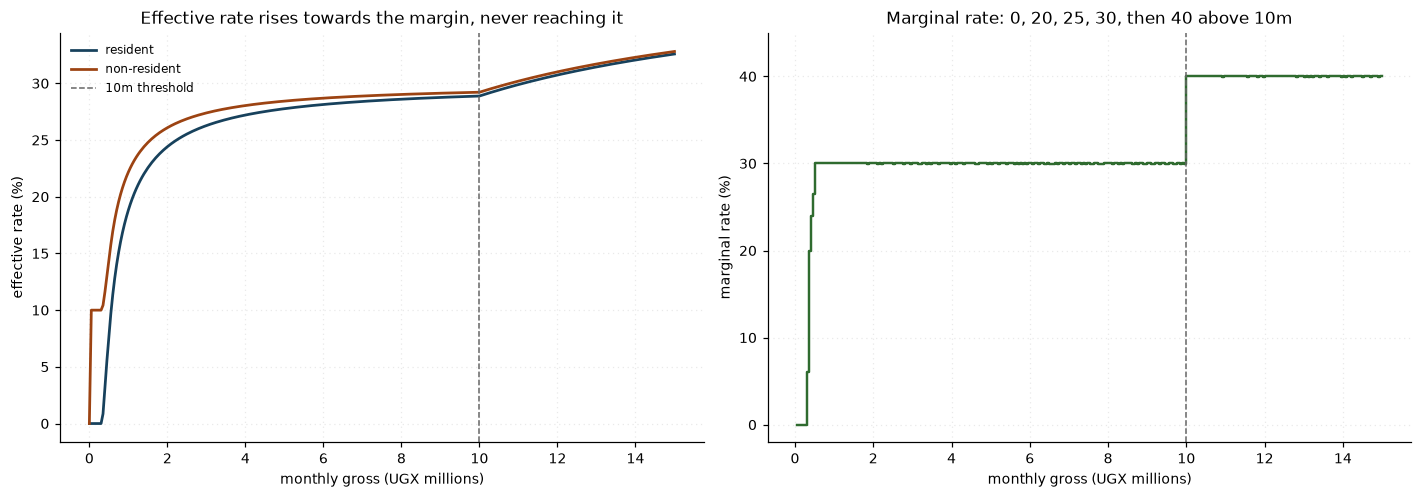

In [11]:
grid = list(range(0, 15_000_001, 50_000))
curves = {status: [float(paye.calculate(TaxContext(
    period=PERIOD, earnings=Money(g), residency=status)).rate) for g in grid]
    for status in (Residency.RESIDENT, Residency.NON_RESIDENT)}

figure, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for index, (status, series) in enumerate(curves.items()):
    axes[0].plot([g / 1e6 for g in grid], [r * 100 for r in series],
                 color=INK[index], lw=1.8, label=status)
axes[0].axvline(10, color="0.4", ls="--", lw=1, label="10m threshold")
axes[0].set_xlabel("monthly gross (UGX millions)")
axes[0].set_ylabel("effective rate (%)")
axes[0].set_title("Effective rate rises towards the margin, never reaching it")
axes[0].legend(fontsize=8)

marginal = [(curves[Residency.RESIDENT][i + 1] * grid[i + 1]
             - curves[Residency.RESIDENT][i] * grid[i]) / 50_000
            for i in range(len(grid) - 1)]
axes[1].step([g / 1e6 for g in grid[1:]], [m * 100 for m in marginal],
             color=INK[2], lw=1.6, where="pre")
axes[1].axvline(10, color="0.4", ls="--", lw=1)
axes[1].set_xlabel("monthly gross (UGX millions)")
axes[1].set_ylabel("marginal rate (%)")
axes[1].set_title("Marginal rate: 0, 20, 25, 30, then 40 above 10m")
axes[1].set_ylim(-2, 45)
figure.tight_layout()
print("saved:", save(figure, "mp2_paye.png").name)
plt.show()

### Schedules that know when they stop

Every schedule carries an **end date** as well as a start. That is what lets
the engine distinguish three different failures, where a "most recent
schedule at or before this date" lookup would silently apply an expired
schedule to a later year and return a confident wrong number.

In [12]:
try:
    paye.calculate(TaxContext(period=dt.date(2000, 1, 1),
                              earnings=Money("500000")))
except NoScheduleForDateError as problem:
    print(f"before everything -> in_gap={problem.in_gap}: {problem}")

gapped = ScheduleSet([
    Schedule(Residency.RESIDENT, dt.date(2020, 7, 1), dt.date(2021, 6, 30),
             SCHEDULES[0].slices, "a closed year"),
    Schedule(Residency.RESIDENT, dt.date(2023, 7, 1), None,
             SCHEDULES[0].slices, "the current year")])
print(f"\ninside a schedule -> "
      f"{gapped.in_force(dt.date(2020, 9, 1), Residency.RESIDENT).span}")
try:
    gapped.in_force(dt.date(2022, 1, 1), Residency.RESIDENT)
except NoScheduleForDateError as problem:
    print(f"in the gap        -> in_gap={problem.in_gap}: {problem}")

before everything -> in_gap=False: 2000-01-01 for a resident is not covered; on file: resident 2012-07-01 to current

inside a schedule -> resident 2020-07-01 to 2021-06-30
in the gap        -> in_gap=True: 2022-01-01 for a resident falls in a gap between schedules; on file: resident 2020-07-01 to 2021-06-30, resident 2023-07-01 to current


## 2. Payroll as a ledger

### The order, and the justification

Local Service Tax is an allowable deduction against employment income, so
PAYE is charged on gross **less** LST — the brief says "applied before PAYE"
and the Local Governments Act agrees. NSSF is the step most often got wrong:
the employee's 5% is charged on the **full gross**, and Uganda does *not*
allow it as a deduction against employment income the way several
neighbouring jurisdictions do, so PAYE and NSSF sit on overlapping bases and
neither reduces the other. The employer's 10% never touches net pay.

In [13]:
payroll = Payroll()
payroll.order()

,#,line,charged on,before PAYE,borne by
0,1,Local Service Tax,gross,yes,employee
1,2,PAYE,gross less LST,—,employee
2,3,NSSF employee 5%,full gross,no,employee
3,4,NSSF employer 10%,full gross,no,employer


In [14]:
slip = payroll.run(TaxContext(period=PERIOD, earnings=Money("2500000"),
                              allowances=Money("300000")))
print(slip.working())

Payroll for 2026-07-01
  Gross pay                                2800000
  less Local Service Tax                    -25000
  less PAYE                                -720750
  less NSSF employee 5%                    -140000
  Net pay                                  1914250
  (take-home 68.37%)
  NSSF employer 10% (employer)               280000
  Total cost of employment                 3080000


In [15]:
slip.to_frame()

,line,amount,charged on,before PAYE,borne by
0,Gross pay,2800000,—,—,—
1,Local Service Tax,-25000,2800000,yes,employee
2,PAYE,-720750,2775000,no,employee
3,NSSF employee 5%,-140000,2800000,no,employee
4,NSSF employer 10%,280000,2800000,no,employer
5,Net pay,1914250,—,—,—


### Why postings instead of subtractions

Each line records the base it was computed from. That makes the overlapping
bases visible in the data rather than implicit in the order of statements.

In [16]:
for posting in slip:
    print(" ", posting)
print()
print(f"PAYE was charged on {slip.line('PAYE').charged_on}, which is gross")
print(f"less the {slip.line('Local Service Tax').amount} of LST.")
print(f"NSSF was charged on {slip.line('NSSF employee 5%').charged_on}, the")
print("full gross — the LST deduction does not reduce it. Two different bases")
print("in the same payslip, which is exactly the thing worth making explicit.")

  Local Service Tax: UGX 25,000 on UGX 2,800,000 (0.89%, borne by the employee)
  PAYE: UGX 720,750 on UGX 2,775,000 (25.97%, borne by the employee)
  NSSF employee 5%: UGX 140,000 on UGX 2,800,000 (5.00%, borne by the employee)
  NSSF employer 10%: UGX 280,000 on UGX 2,800,000 (10.00%, borne by the employer)

PAYE was charged on UGX 2,775,000, which is gross
less the UGX 25,000 of LST.
NSSF was charged on UGX 2,800,000, the
full gross — the LST deduction does not reduce it. Two different bases
in the same payslip, which is exactly the thing worth making explicit.


In [17]:
no_lst = Payroll(lst=False).run(TaxContext(period=PERIOD,
                                           earnings=Money("2800000")))
print(f"PAYE with LST first : {slip.paye.payable}")
print(f"PAYE without LST    : {no_lst.paye.payable}")
print(f"difference          : {no_lst.paye.payable - slip.paye.payable}")
print(f"LST itself          : {slip.line('Local Service Tax').amount}")
print("\nAt a 30% marginal rate, deducting LST first returns 30% of it through")
print("a smaller PAYE charge. Getting the order wrong overstates the tax.")

PAYE with LST first : UGX 720,750
PAYE without LST    : UGX 728,250
difference          : UGX 7,500
LST itself          : UGX 25,000

At a 30% marginal rate, deducting LST first returns 30% of it through
a smaller PAYE charge. Getting the order wrong overstates the tax.


In [18]:
ladder = []
for gross in (500_000, 1_000_000, 2_000_000, 5_000_000, 12_000_000):
    row = payroll.run(TaxContext(period=PERIOD, earnings=Money(gross)))
    ladder.append({"gross": gross,
                   "LST": int(row.line("Local Service Tax").amount.amount),
                   "PAYE": int(row.paye.payable.amount),
                   "NSSF 5%": int(row.line("NSSF employee 5%").amount.amount),
                   "net": int(row.net.amount),
                   "take-home": f"{row.take_home:.1%}",
                   "employer cost": int(row.employer_cost.amount)})
pd.DataFrame(ladder).set_index("gross")

,LST,PAYE,NSSF 5%,net,take-home,employer cost
gross,,,,,,
500000,10000,35250,25000,429750,86.0%,550000
1000000,15000,183750,50000,751250,75.1%,1100000
2000000,25000,480750,100000,1394250,69.7%,2200000
5000000,25000,1380750,250000,3344250,66.9%,5500000
12000000,25000,3678250,600000,7696750,64.1%,13200000


## 3. VAT

### Zero-rated is not exempt

Both charge no output VAT, so a sales report cannot tell them apart. A
**zero-rated** supply is taxable at 0%, so input VAT incurred making it stays
recoverable. An **exempt** supply is outside the VAT system, so the input VAT
attributable to it is blocked and becomes a cost. Collapsing the two always
overstates the refund.

In [19]:
pd.DataFrame([{"supply": str(kind), "output rate": f"{kind.output_rate:.0%}",
               "input VAT recoverable": kind.recovers_input}
              for kind in SupplyKind])

,supply,output rate,input VAT recoverable
0,standard-rated,18%,True
1,zero-rated,0%,True
2,exempt,0%,False


In [20]:
documents = [
    Document("INV-001 local sales", Money("10000000"), SupplyKind.STANDARD),
    Document("INV-002 coffee export", Money("4000000"), SupplyKind.ZERO_RATED),
    Document("INV-003 financial services", Money("3000000"), SupplyKind.EXEMPT),
    Document("PUR-010 packaging", Money("5000000"), SupplyKind.STANDARD,
             inbound=True),
    Document("PUR-011 export freight", Money("2000000"), SupplyKind.ZERO_RATED,
             inbound=True, vat_shown=Money("360000")),
    Document("PUR-012 branch costs", Money("1500000"), SupplyKind.EXEMPT,
             inbound=True, vat_shown=Money("270000")),
]
for document in documents:
    print(f"  {document}")

position = VatTax().position(documents)
print()
print(position.working())

  INV-001 local sales (sale, standard-rated): UGX 10,000,000 + UGX 1,800,000 VAT
  INV-002 coffee export (sale, zero-rated): UGX 4,000,000 + UGX 0 VAT
  INV-003 financial services (sale, exempt): UGX 3,000,000 + UGX 0 VAT
  PUR-010 packaging (purchase, standard-rated): UGX 5,000,000 + UGX 900,000 VAT
  PUR-011 export freight (purchase, zero-rated): UGX 2,000,000 + UGX 360,000 VAT
  PUR-012 branch costs (purchase, exempt): UGX 1,500,000 + UGX 270,000 VAT

  Output VAT on sales                       1800000
  less recoverable input VAT               -1260000
  = net VAT payable                         540000
  input VAT blocked (exempt)                 270000


In [21]:
position.by_kind

,supply,net sales,output VAT,input VAT,input recoverable
0,standard-rated,10000000,1800000,900000,True
1,zero-rated,4000000,0,360000,True
2,exempt,3000000,0,270000,False


In [22]:
print("If the exempt supplies were wrongly treated as zero-rated:")
print(f"  the blocked {position.blocked} would have been reclaimed,")
print(f"  turning {position.net} payable into "
      f"{position.net - position.blocked}.")
print("  An understatement of the liability — and what an audit looks for.")

If the exempt supplies were wrongly treated as zero-rated:
  the blocked UGX 270,000 would have been reclaimed,
  turning UGX 540,000 payable into UGX 270,000.
  An understatement of the liability — and what an audit looks for.


## 4. Corporate income tax

In [23]:
costs = [Outgoing("staff costs", Money("40000000")),
         Outgoing("rent", Money("12000000")),
         Outgoing("accounting depreciation", Money("8000000"), allowable=False),
         Outgoing("URA penalties", Money("2000000"), allowable=False)]
for cost in costs:
    print(f"  {cost}")

company = CompanyTax()
result = company.calculate(TaxContext(period=PERIOD, receipts=Money("100000000"),
                                      settings={"outgoings": costs}))
print()
print(result.working())

  staff costs: UGX 40,000,000 (allowable)
  rent: UGX 12,000,000 (allowable)
  accounting depreciation: UGX 8,000,000 (DISALLOWED)
  URA penalties: UGX 2,000,000 (DISALLOWED)

Corporate income tax on UGX 48,000,000
  receipts less allowable outgoings: UGX 48,000,000 @ 0.30 = UGX 14,400,000
  = UGX 14,400,000   (effective 30.00%)
  note: UGX 10,000,000 disallowed and added back


In [24]:
book = Money("100000000")
for cost in costs:
    book = book - cost.amount
print(f"accounting profit : {book}")
print(f"chargeable income : {result.charged_on}")
print(f"added back        : {result.charged_on - book}")

loss = company.calculate(TaxContext(period=PERIOD, receipts=Money("10000000"),
                                    outgoings=Money("25000000")))
print(f"\na loss charges nothing: base {loss.charged_on}, due {loss.payable}")

accounting profit : UGX 38,000,000
chargeable income : UGX 48,000,000
added back        : UGX 10,000,000

a loss charges nothing: base UGX 0, due UGX 0


## Extension: employment or consultancy?

A company needs someone's work. It can put them on the payroll, or engage
them as an independent consultant. The two are taxed very differently, and
the comparison only means anything if the **company's outlay is held
constant** — otherwise one route simply buys more labour.

* **Employment.** A salary of `S` costs `S` plus 10% employer NSSF, so an
  outlay of `C` supports `S = C / 1.1`. The worker bears LST, PAYE and 5%
  employee NSSF.
* **Consultancy.** The whole outlay is paid as fees. 6% is withheld at
  source, and the consultant is assessed on fees less business expenses at
  the same progressive individual rates — with the withholding a **credit**
  against that liability, not an extra charge.

In [25]:
planner = EngagementPlanner(PERIOD)
print(repr(planner))
print()
result = planner.compare(Money("5000000"))
print(result.employment.working())
print()
print(result.consultancy.working())

EngagementPlanner(2026-07-01, allowance=30%)

Employment: the company spends UGX 5,000,000 a month
    worker is paid                            4545454
    Local Service Tax                           25000
    PAYE                                      1244386
    NSSF employee 5%                           227272
    NSSF employer 10%                          454545
    total tax and contributions               1951203
    worker keeps                              3048796
    (39.02% of outlay to tax; 60.98% kept as cash)
    plus UGX 681,817 into NSSF, which is a saving rather than a cost

Consultancy: the company spends UGX 5,000,000 a month
    worker is paid                            5000000
    income tax on business income              938250
    total tax and contributions                938250
    worker keeps                              4061750
    (18.76% of outlay to tax; 81.24% kept as cash)


In [26]:
result.to_frame()

,cash in hand,NSSF saved,cash + saving,total tax,tax as % of outlay
arrangement,,,,,
Employment,3048796,681817,3730613,1951203,39.02%
Consultancy,4061750,0,4061750,938250,18.76%


In [27]:
print(f"better on cash in hand : {result.better_for_cash}, "
      f"by {result.cash_margin}")
print(f"better on cash + NSSF  : {result.better_for_value}, "
      f"by {result.value_margin}")
print(f"counting NSSF closes   : {result.nssf_closes} of the cash gap")

better on cash in hand : Consultancy, by UGX 1,012,954
better on cash + NSSF  : Consultancy, by UGX 331,137
counting NSSF closes   : UGX 681,817 of the cash gap


In [28]:
sweep = planner.sweep([Money(str(v)) for v in
                       (1_000_000, 2_000_000, 5_000_000, 8_000_000,
                        12_000_000, 20_000_000)])
sweep

,employee keeps,consultant keeps,better on cash,cash margin,employee NSSF,employee cash+NSSF,better on total value,value margin
monthly outlay,,,,,,,,
1000000,692159,901750,Consultancy,209591,136363,828522,Consultancy,73228
2000000,1276068,1691750,Consultancy,415682,272727,1548795,Consultancy,142955
5000000,3048796,4061750,Consultancy,1012954,681817,3730613,Consultancy,331137
8000000,4821523,6431750,Consultancy,1610227,1090908,5912431,Consultancy,519319
12000000,7096750,9591750,Consultancy,2495000,1636363,8733113,Consultancy,858637
20000000,11096752,15511750,Consultancy,4414998,2727271,13824023,Consultancy,1687727


### Testing the obvious explanation, and finding it wrong

The natural guess is that the consultant's expense allowance drives the
result. It does not. The sweep below holds everything else constant and
varies the allowance from zero upwards.

In [29]:
sensitivity = planner.sensitivity(
    Money("5000000"),
    [Decimal(v) for v in ("0.00", "0.10", "0.20", "0.30", "0.40", "0.50")])
sensitivity

,consultant keeps,employee keeps,better for cash
expense allowance,,,
0%,3611750,3048796,Consultancy
10%,3761750,3048796,Consultancy
20%,3911750,3048796,Consultancy
30%,4061750,3048796,Consultancy
40%,4211750,3048796,Consultancy
50%,4361750,3048796,Consultancy


In [30]:
print("Consultancy keeps more cash at EVERY allowance, including zero.")
print("So the allowance moves the margin but not the ranking, and the real")
print("driver is something else: employment carries 15% NSSF (5% employee")
print("plus 10% employer) that consultancy does not.")
print()
print("But NSSF is not a tax. It is the worker's own money, held for later.")
print("Counting it as value rather than cost is what the 'cash + saving'")
print(f"column does, and it closes {result.nssf_closes} of a "
      f"{result.cash_margin} gap —")
print("about two thirds of it. The cash comparison alone is misleading.")

Consultancy keeps more cash at EVERY allowance, including zero.
So the allowance moves the margin but not the ranking, and the real
driver is something else: employment carries 15% NSSF (5% employee
plus 10% employer) that consultancy does not.

But NSSF is not a tax. It is the worker's own money, held for later.
Counting it as value rather than cost is what the 'cash + saving'
column does, and it closes UGX 681,817 of a UGX 1,012,954 gap —
about two thirds of it. The cash comparison alone is misleading.


saved: mp2_engagement.png


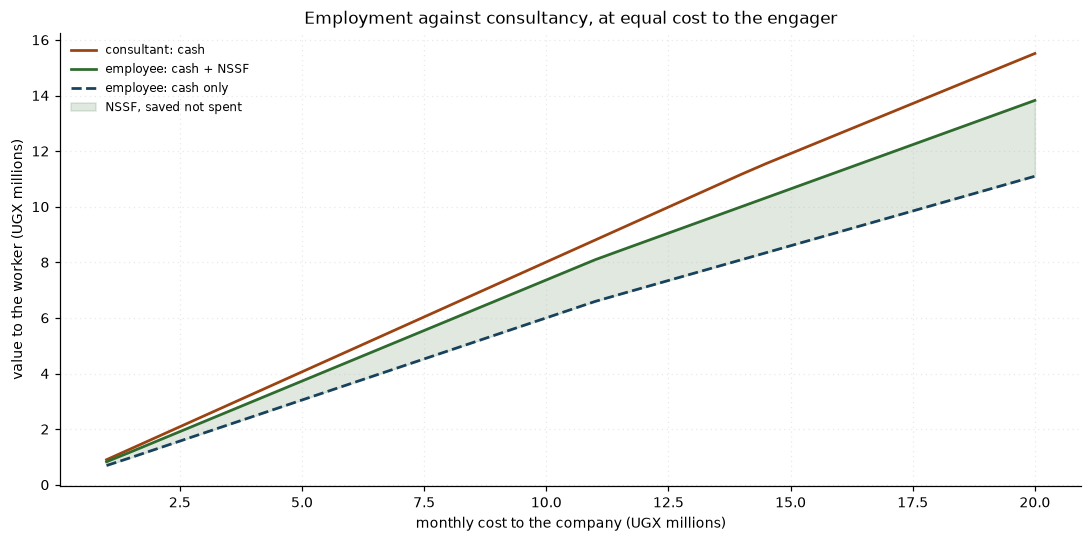

In [31]:
outlays = list(range(1_000_000, 20_000_001, 500_000))
employee_cash, employee_value, consultant_cash = [], [], []
for amount in outlays:
    row = planner.compare(Money(str(amount)))
    employee_cash.append(int(row.employment.in_hand.amount))
    employee_value.append(int(row.employment.total_value.amount))
    consultant_cash.append(int(row.consultancy.in_hand.amount))

figure, ax = plt.subplots(figsize=(10, 5))
ax.plot([o / 1e6 for o in outlays], [v / 1e6 for v in consultant_cash],
        color=INK[1], lw=1.8, label="consultant: cash")
ax.plot([o / 1e6 for o in outlays], [v / 1e6 for v in employee_value],
        color=INK[2], lw=1.8, label="employee: cash + NSSF")
ax.plot([o / 1e6 for o in outlays], [v / 1e6 for v in employee_cash],
        color=INK[0], lw=1.8, ls="--", label="employee: cash only")
ax.fill_between([o / 1e6 for o in outlays],
                [v / 1e6 for v in employee_cash],
                [v / 1e6 for v in employee_value],
                color=INK[2], alpha=0.15, label="NSSF, saved not spent")
ax.set_xlabel("monthly cost to the company (UGX millions)")
ax.set_ylabel("value to the worker (UGX millions)")
ax.set_title("Employment against consultancy, at equal cost to the engager")
ax.legend(fontsize=8)
figure.tight_layout()
print("saved:", save(figure, "mp2_engagement.png").name)
plt.show()

### What must be said alongside any of this

In [32]:
for index, caveat in enumerate(Comparison.caveats(), 1):
    print(f"{index}. {caveat}\n")

1. Whether a relationship is employment or consultancy is a question of fact — control, integration, who bears the risk — decided on substance, not a label chosen for tax reasons. URA can re-characterise an arrangement.

2. The consultant's expense allowance is illustrative, not statutory; a real consultant deducts actual allowable costs. It shifts the margin but not the ranking — consultancy keeps more cash even at a zero allowance.

3. Employment NSSF is a retirement asset, not a pure cost, and it is the single biggest driver of the gap here. Comparing cash in hand alone understates employment substantially; read the cash-plus-saving column instead.

4. A consultant above the VAT registration threshold must register and charge VAT, which is not modelled.

5. Employment carries rights — leave, notice, injury cover — with real value that no tax calculation captures.



The first caveat is the most important and is not a technicality. Whether a
relationship **is** employment or consultancy is a question of fact, decided
on the substance of the arrangement — who controls the work, how integrated
the person is, who carries the risk — and not on the label the parties find
convenient. URA can and does re-characterise arrangements, with the tax and
penalties falling on the engager. This notebook answers the narrow question
"what would each cost if both were genuinely available", which is not the
same as "which should we choose".

## One contract, five taxes

In [33]:
shared = TaxContext(period=PERIOD, earnings=Money("3000000"),
                    receipts=Money("50000000"), outgoings=Money("20000000"),
                    documents=tuple(documents))
pd.DataFrame([{
    "tax": outcome.tax, "charged on": int(outcome.charged_on.amount),
    "payable": int(outcome.payable.amount), "rate": f"{outcome.rate:.2%}",
} for outcome in (tax.calculate(shared) for tax in
                  (PayeTax(), VatTax(), CompanyTax(), WithholdingTax(),
                   BusinessIncomeTax()))]).set_index("tax")

,charged on,payable,rate
tax,,,
PAYE,3000000,788250,26.28%
VAT,10000000,540000,5.40%
Corporate income tax,30000000,9000000,30.00%
Withholding tax,50000000,3000000,6.00%
Business income tax,35000000,9158988,26.17%


## Validation: nothing fails silently

In [34]:
for label, attempt in [
    ("negative pay", lambda: TaxContext(period=PERIOD, earnings=Money("-1"))),
    ("unknown residency", lambda: TaxContext(period=PERIOD,
                                             earnings=Money("1"),
                                             residency="lunar")),
    ("a float VAT rate", lambda: VatTax(rate=0.18)),
    ("an unknown supply", lambda: Document("X", Money("100"), kind="standard")),
    ("a negative cost", lambda: Outgoing("odd", Money("-1"))),
    ("an uncovered date", lambda: PayeTax().calculate(
        TaxContext(period=dt.date(1999, 1, 1), earnings=Money("500000")))),
    ("a float amount", lambda: Money(1.5)),
    ("an impossible allowance", lambda: BusinessIncomeTax(
        expense_allowance=Decimal("1.5"))),
]:
    try:
        attempt()
        print(f"  {label:<24} -> NOT CAUGHT")
    except (TaxError, ValueError, TypeError) as problem:
        print(f"  {label:<24} -> {type(problem).__name__}: "
              f"{str(problem)[:52]}")

  negative pay             -> InvalidIncomeError: earnings cannot be negative: UGX -1
  unknown residency        -> ValueError: residency must be 'resident' or 'non-resident', got 
  a float VAT rate         -> BadRate: the VAT rate must be a Decimal: 0.18
  an unknown supply        -> UnknownSupply: unknown supply type 'standard'
  a negative cost          -> InvalidIncomeError: a cost cannot be negative: UGX -1
  an uncovered date        -> NoScheduleForDateError: 1999-01-01 for a resident is not covered; on file: r
  a float amount           -> TypeError: Money does not accept a float: round(2.675, 2) gives
  an impossible allowance  -> BadRate: the allowance must lie in 0..1: 1.5


## Discussion

### 1. Why is `float` unsafe for tax computation?

Because binary floating point cannot represent most decimal fractions, and
tax is defined in decimal. The three demonstrations above are distinct
failures. The first would reach a payslip directly: `round(2.675, 2)` returns
`2.67`, because the nearest double to 2.675 lies fractionally below it. A
round-half-up rule applied to a float therefore rounds half *down* whenever
the stored value falls on the low side, and nothing in the decimal digits
predicts which way it will go. The outcome is a figure wrong by one shilling,
inconsistently, with no diagnosable cause — the worst available failure mode
in a system whose output somebody is legally obliged to pay.

The second is specific to payroll. Float addition is not associative, so a
payslip summing LST, PAYE and NSSF would produce a total that depends on the
order the lines were added. Two faithful implementations of the same
documented rules could disagree, and no reading of the rules would settle
which was correct. The third, accumulation, is worst in exactly the
high-volume runs where it is least likely to be noticed.

`Decimal` fixes all three by storing decimal digits and letting the rounding
rule be stated and not inherited from the hardware. This build states it
as **truncation towards zero**, which never charges a shilling the
computation did not fully earn. Truncation is not neutral, which is why the
notebook measures it: across 2,000 payslips it collected under a shilling per
payslip less than half-up — small, one-sided, and scaling with the payroll.
Stating a rounding policy and then quantifying its bias seems to me the
minimum standard for a calculation of this kind, because the bias is
invisible in any single result and perfectly visible in the aggregate.

`Money` refuses `float` at construction and refuses float rates in
multiplication. Refusing rather than coercing matters: `Money(335000.50)`
could silently become `Money('335000')`, and a system that quietly discards
half a shilling is worse than one that stops and says why.

### 2. Where is inheritance justified, and where was it deliberately avoided?

**Justified: `Tax`.** `PayeTax`, `VatTax`, `CompanyTax`, `WithholdingTax` and
`BusinessIncomeTax` all subclass it. What they share is not behaviour but a
*contract* — `calculate(ctx) -> TaxResult` — and the base class deliberately
holds no arithmetic, because the five do mechanically unrelated things. The
payoff is visible in the summary table above, which loops over all five, and
in the planner, which accepts any `Tax` without knowing which it has.

**Deliberately avoided: `BusinessIncomeTax` does not inherit from
`PayeTax`.** This was the closest call in the project. A consultant is
charged at *exactly* the same progressive rates as an employee, so
`class BusinessIncomeTax(PayeTax)` would have reused the band machinery and
looked natural. It would also have been wrong. A consultant is not an
employee: the base is fees less business expenses instead of gross pay,
the assessment is annual rather than monthly, no NSSF applies, no Local
Service Tax applies, and the withholding credit has no analogue in PAYE.
Subclassing would have inherited `calculate` and then had to override
essentially all of it, which is the clearest possible signal that the
relationship is not "is a". So the class **composes** a `PayeTax` internally
and delegates the band arithmetic to it. Reuse without the false claim of
kinship — and if PAYE later gains an employment-specific rule, the consultant
calculation does not silently acquire it.

**Deliberately avoided: `Money` does not subclass `Decimal`.** Inheriting
would have made the arithmetic work for free, and would also have meant
`Money * Money` quietly returning a bare `Decimal`, `Money + 0.5` admitting a
float through an inherited operator, and the truncation policy being
bypassable by any inherited method. The purpose of the type is its ability to
*refuse*, and a subclass cannot refuse what its parent permits.

**Deliberately avoided: `Recorder` does not subclass the live caller** in
mini-project 1. They share an interface and no implementation at all. A
subclass would inherit a session, a schedule and a timeout the recorder has
no use for, and would invite someone to call an inherited method that makes a
real request from an object whose entire purpose is not to.

The test running through all four: inherit where the subtypes owe a caller
the same promise; compose where they merely happen to need similar code.

## Testing

`tests/test_tax.py` covers the band edges the brief lists and the
property-based checks it asks for with `hypothesis` — tax non-negative,
monotonic in income, never exceeding income. The cell below re-runs the
three inline over a wide sample.

In [35]:
random.seed(2026)
sample = sorted(random.sample(range(0, 80_000_000), 500) + edges)
charges = [paye.calculate(TaxContext(period=PERIOD,
                                     earnings=Money(g))).payable for g in sample]

non_negative = all(not c.is_negative() for c in charges)
within = all(c <= Money(g) for c, g in zip(charges, sample))
rising = all(b >= a for a, b in zip(charges, charges[1:]))

print(f"over {len(sample)} incomes from 0 to 80,000,000:")
print(f"  never negative       : {non_negative}")
print(f"  never exceeds income : {within}")
print(f"  monotonic            : {rising}")
assert non_negative and within and rising
print("\nhypothesis checks the same three over generated inputs in")
print("tests/test_tax.py, which is stricter than this fixed sample.")

over 506 incomes from 0 to 80,000,000:
  never negative       : True
  never exceeds income : True
  monotonic            : True

hypothesis checks the same three over generated inputs in
tests/test_tax.py, which is stricter than this fixed sample.
